# ExpertFinder · Prototipo de administración del conocimiento (TalentTech Consulting)
Notebook de ejecución para **Google Colab**. Recorre los componentes del sistema con datos simulados: base de conocimiento y grafo, clasificación de documentos, búsqueda de especialistas, recomendación, asistente RAG y evaluación.

**Antes de ejecutar en Colab:** sube la carpeta del proyecto (zip) o clona tu repositorio de GitHub en la celda 1.

In [1]:
# 1) Obtener el proyecto (Colab): clonar el repositorio o subir el zip. En local, esta celda no hace nada.
import os, sys, subprocess
if not os.path.exists('src') and os.path.exists('../src'):
    os.chdir('..')
if not os.path.exists('src'):
    if os.path.exists('expertfinder-km'):
        os.chdir('expertfinder-km')
    else:
        # Opción A: repositorio propio  ->  !git clone https://github.com/<usuario>/expertfinder-km.git && cd expertfinder-km
        # Opción B: subir el zip
        from google.colab import files
        z = files.upload(); name = list(z)[0]
        subprocess.run(['unzip', '-q', name]); os.chdir('expertfinder-km')
print(os.getcwd())

/home/claude/expertfinder-km


In [2]:
!pip install -q -r requirements.txt

## 2. Datos simulados y base de conocimiento
Se generan 30 empleados, 12 proyectos, 18 incidentes y 168 documentos coherentes con la empresa. Los datos son ficticios.

In [3]:
from src.data_gen import generar
print(generar())
import pandas as pd
pd.read_csv('data/empleados.csv').head()

{'empleados': 30, 'documentos': 168, 'incidentes': 18, 'proyectos': 12}


,id,nombre,puesto,departamento,ingreso,disponibilidad,arquetipo
0,EMP-001,Ana Torres,Desarrollador/a Python,Desarrollo de Software,2023-02-01,parcial,dev_python
1,EMP-002,Luis Pérez,Especialista en bases de datos,Desarrollo de Software,2022-04-23,ocupado,dba
2,EMP-003,Valeria Montoya,Analista de datos,Datos y Analítica,2018-02-13,disponible,analista
3,EMP-004,Diego Herrera,Científico/a de datos,Datos y Analítica,2024-02-13,parcial,cientifico
4,EMP-005,Camila Rojas,Desarrollador/a Full Stack,Desarrollo de Software,2021-05-03,parcial,fullstack


In [4]:
import json, collections
docs = json.load(open('data/documentos.json', encoding='utf-8'))
print(collections.Counter(d['categoria'] for d in docs))
print(docs[0]['titulo']); print(docs[0]['texto'][:400])

Counter({'Certificado o constancia': 84, 'CV o perfil profesional': 30, 'Ticket de incidente': 18, 'Minuta de reunión': 14, 'Informe de cierre de proyecto': 12, 'Manual o política interna': 10})
Certificado Machine Learning Specialization – Natalia Fuentes
CERTIFICADO
DeepLearning.AI hace constar que Natalia Fuentes aprobó el examen de la certificación «Machine Learning Specialization». Fecha de obtención: 11/10/2025. Vigencia: sin fecha de vencimiento. Folio TT-891937. La certificación avala conocimientos de Machine Learning.


## 3. Sistema integrado y grafo de conocimiento

In [5]:
from src.sistema import Sistema
S = Sistema()
r = S.kb.resumen()
print('Nodos:', r['nodos'], '| Relaciones:', r['relaciones'])
print(r['tipos_nodo']); print(r['tipos_relacion'])

Nodos: 335 | Relaciones: 1277
{'Documento': 168, 'Empleado': 30, 'Tecnología': 25, 'Capacitación': 24, 'Incidente': 18, 'Certificación': 17, 'Habilidad': 15, 'Proyecto': 12, 'Cliente': 10, 'Categoría': 6, 'Área': 5, 'Departamento': 5}
{'menciona': 376, 'clasificado_como': 168, 'respalda': 132, 'participó_en': 90, 'acredita': 84, 'tiene_habilidad': 63, 'documenta': 62, 'completó': 58, 'usa': 39, 'pertenece_a': 30, 'desarrolla': 26, 'posee': 26, 'es_un_tipo_de': 25, 'resolvió': 18, 'ocurrió_en': 18, 'involucra': 18, 'avala': 17, 'pertenece_al_área': 15, 'solicitado_por': 12}


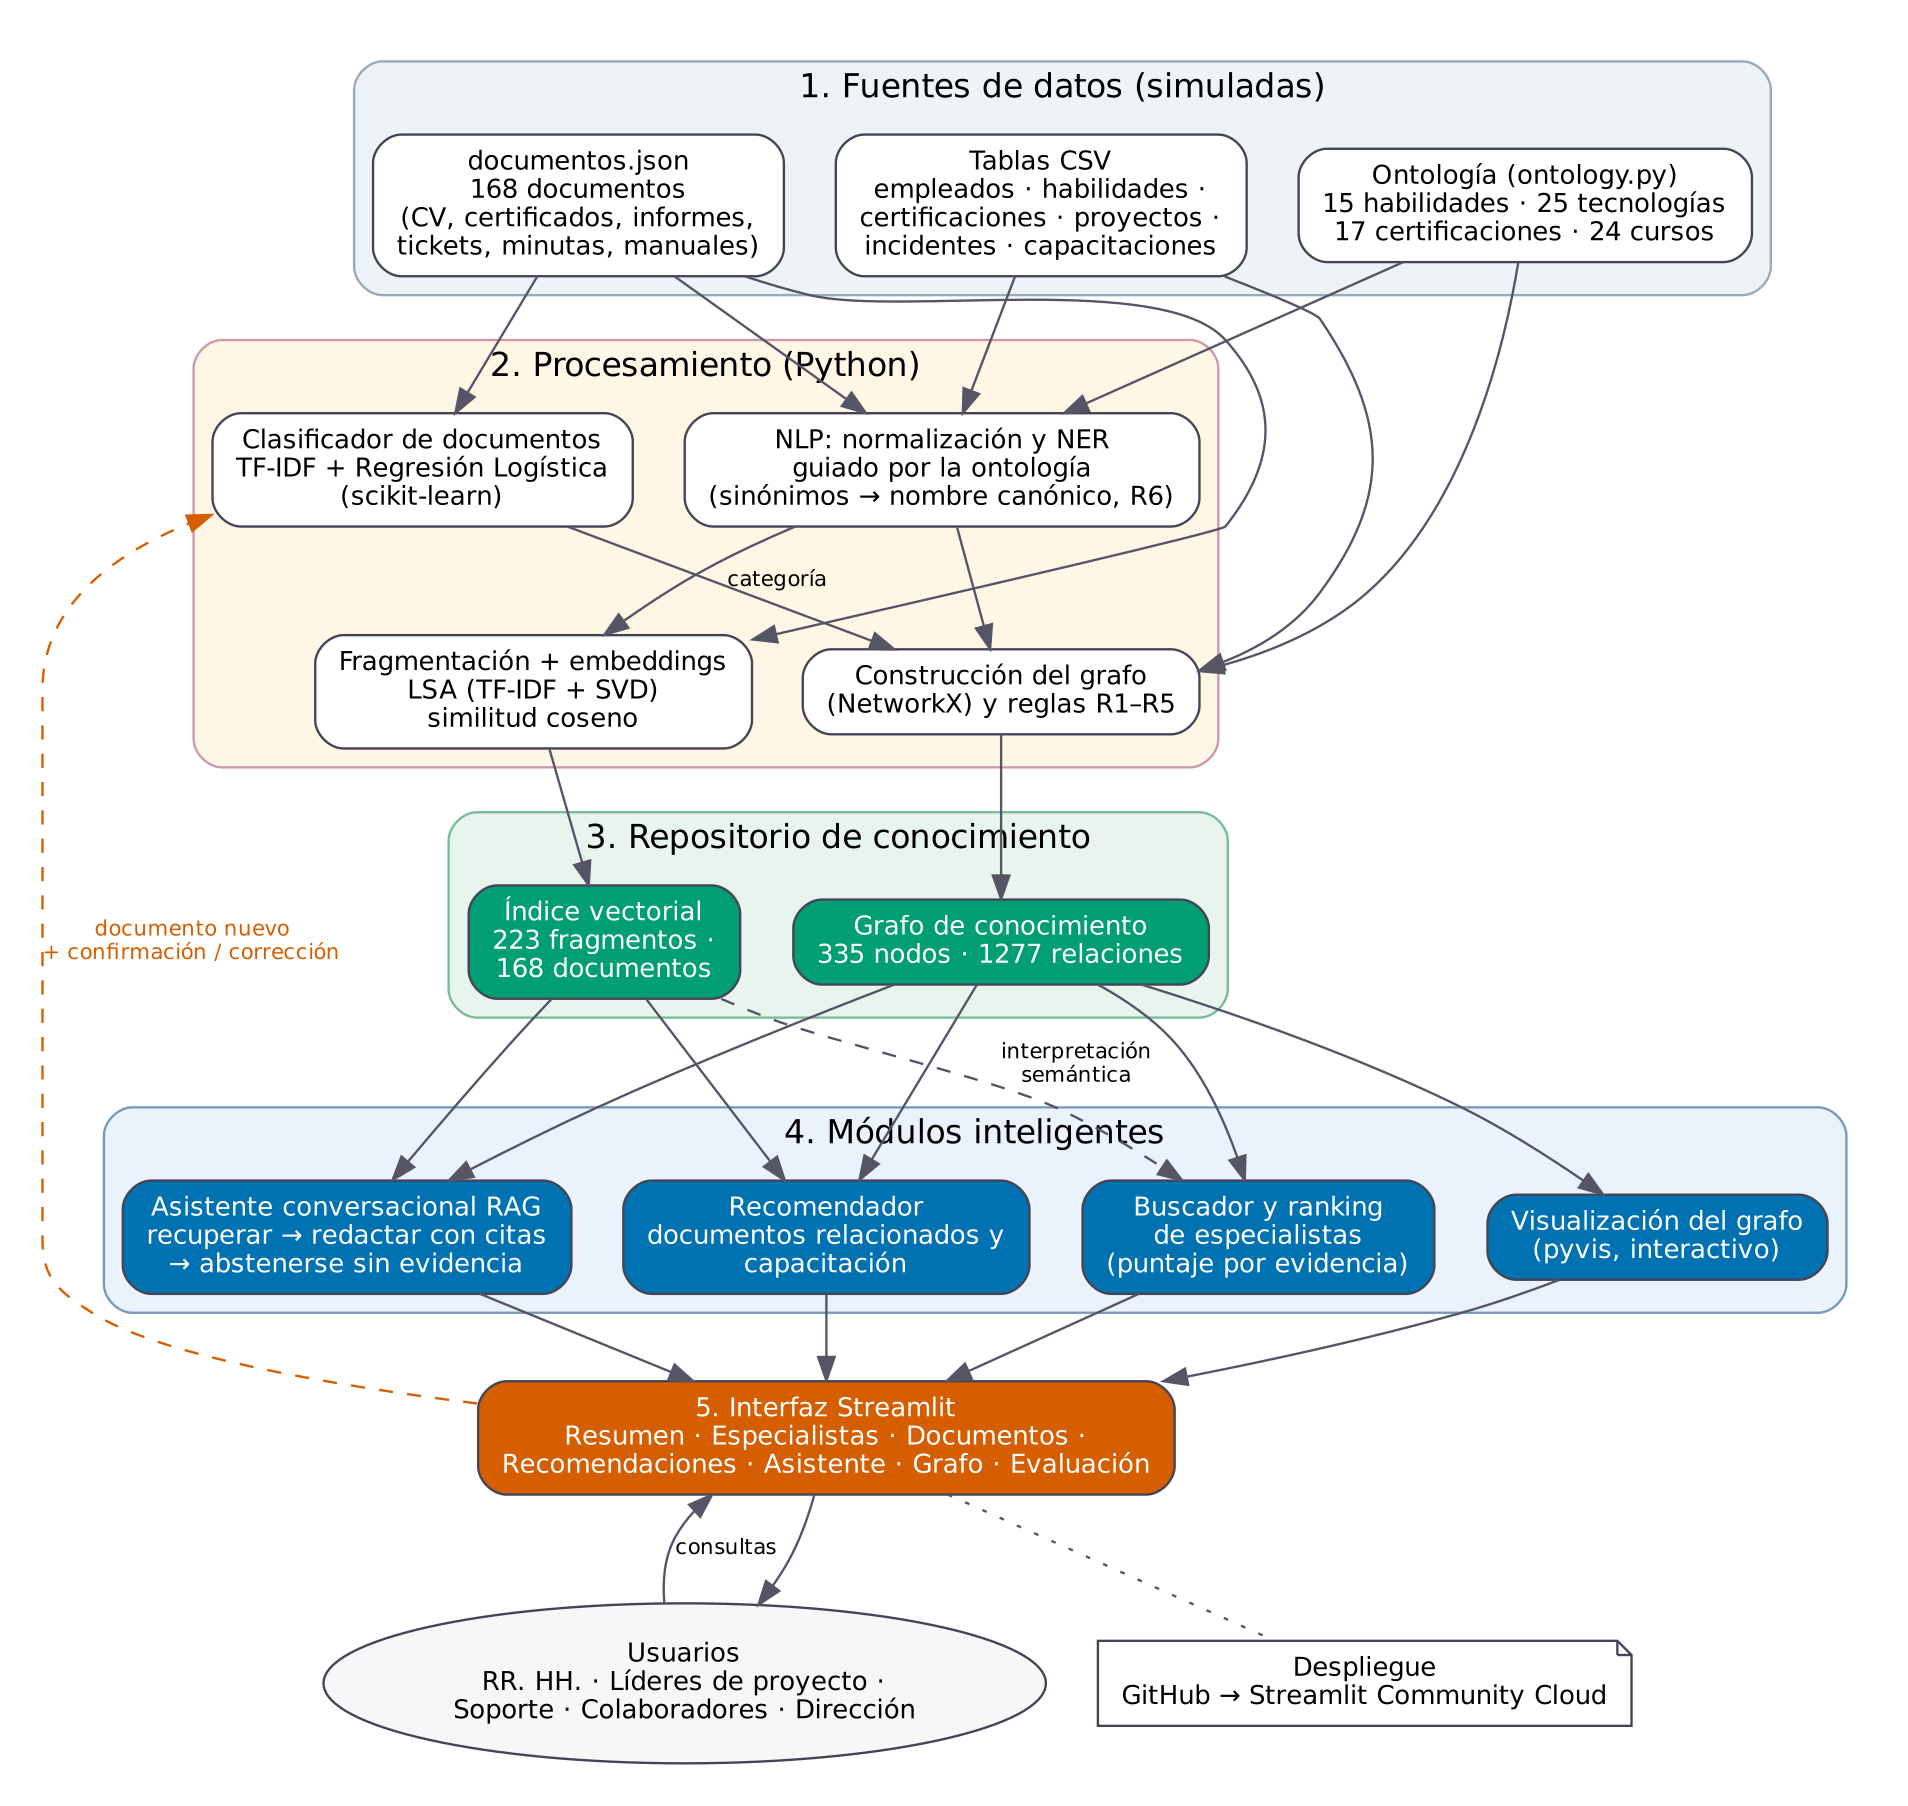

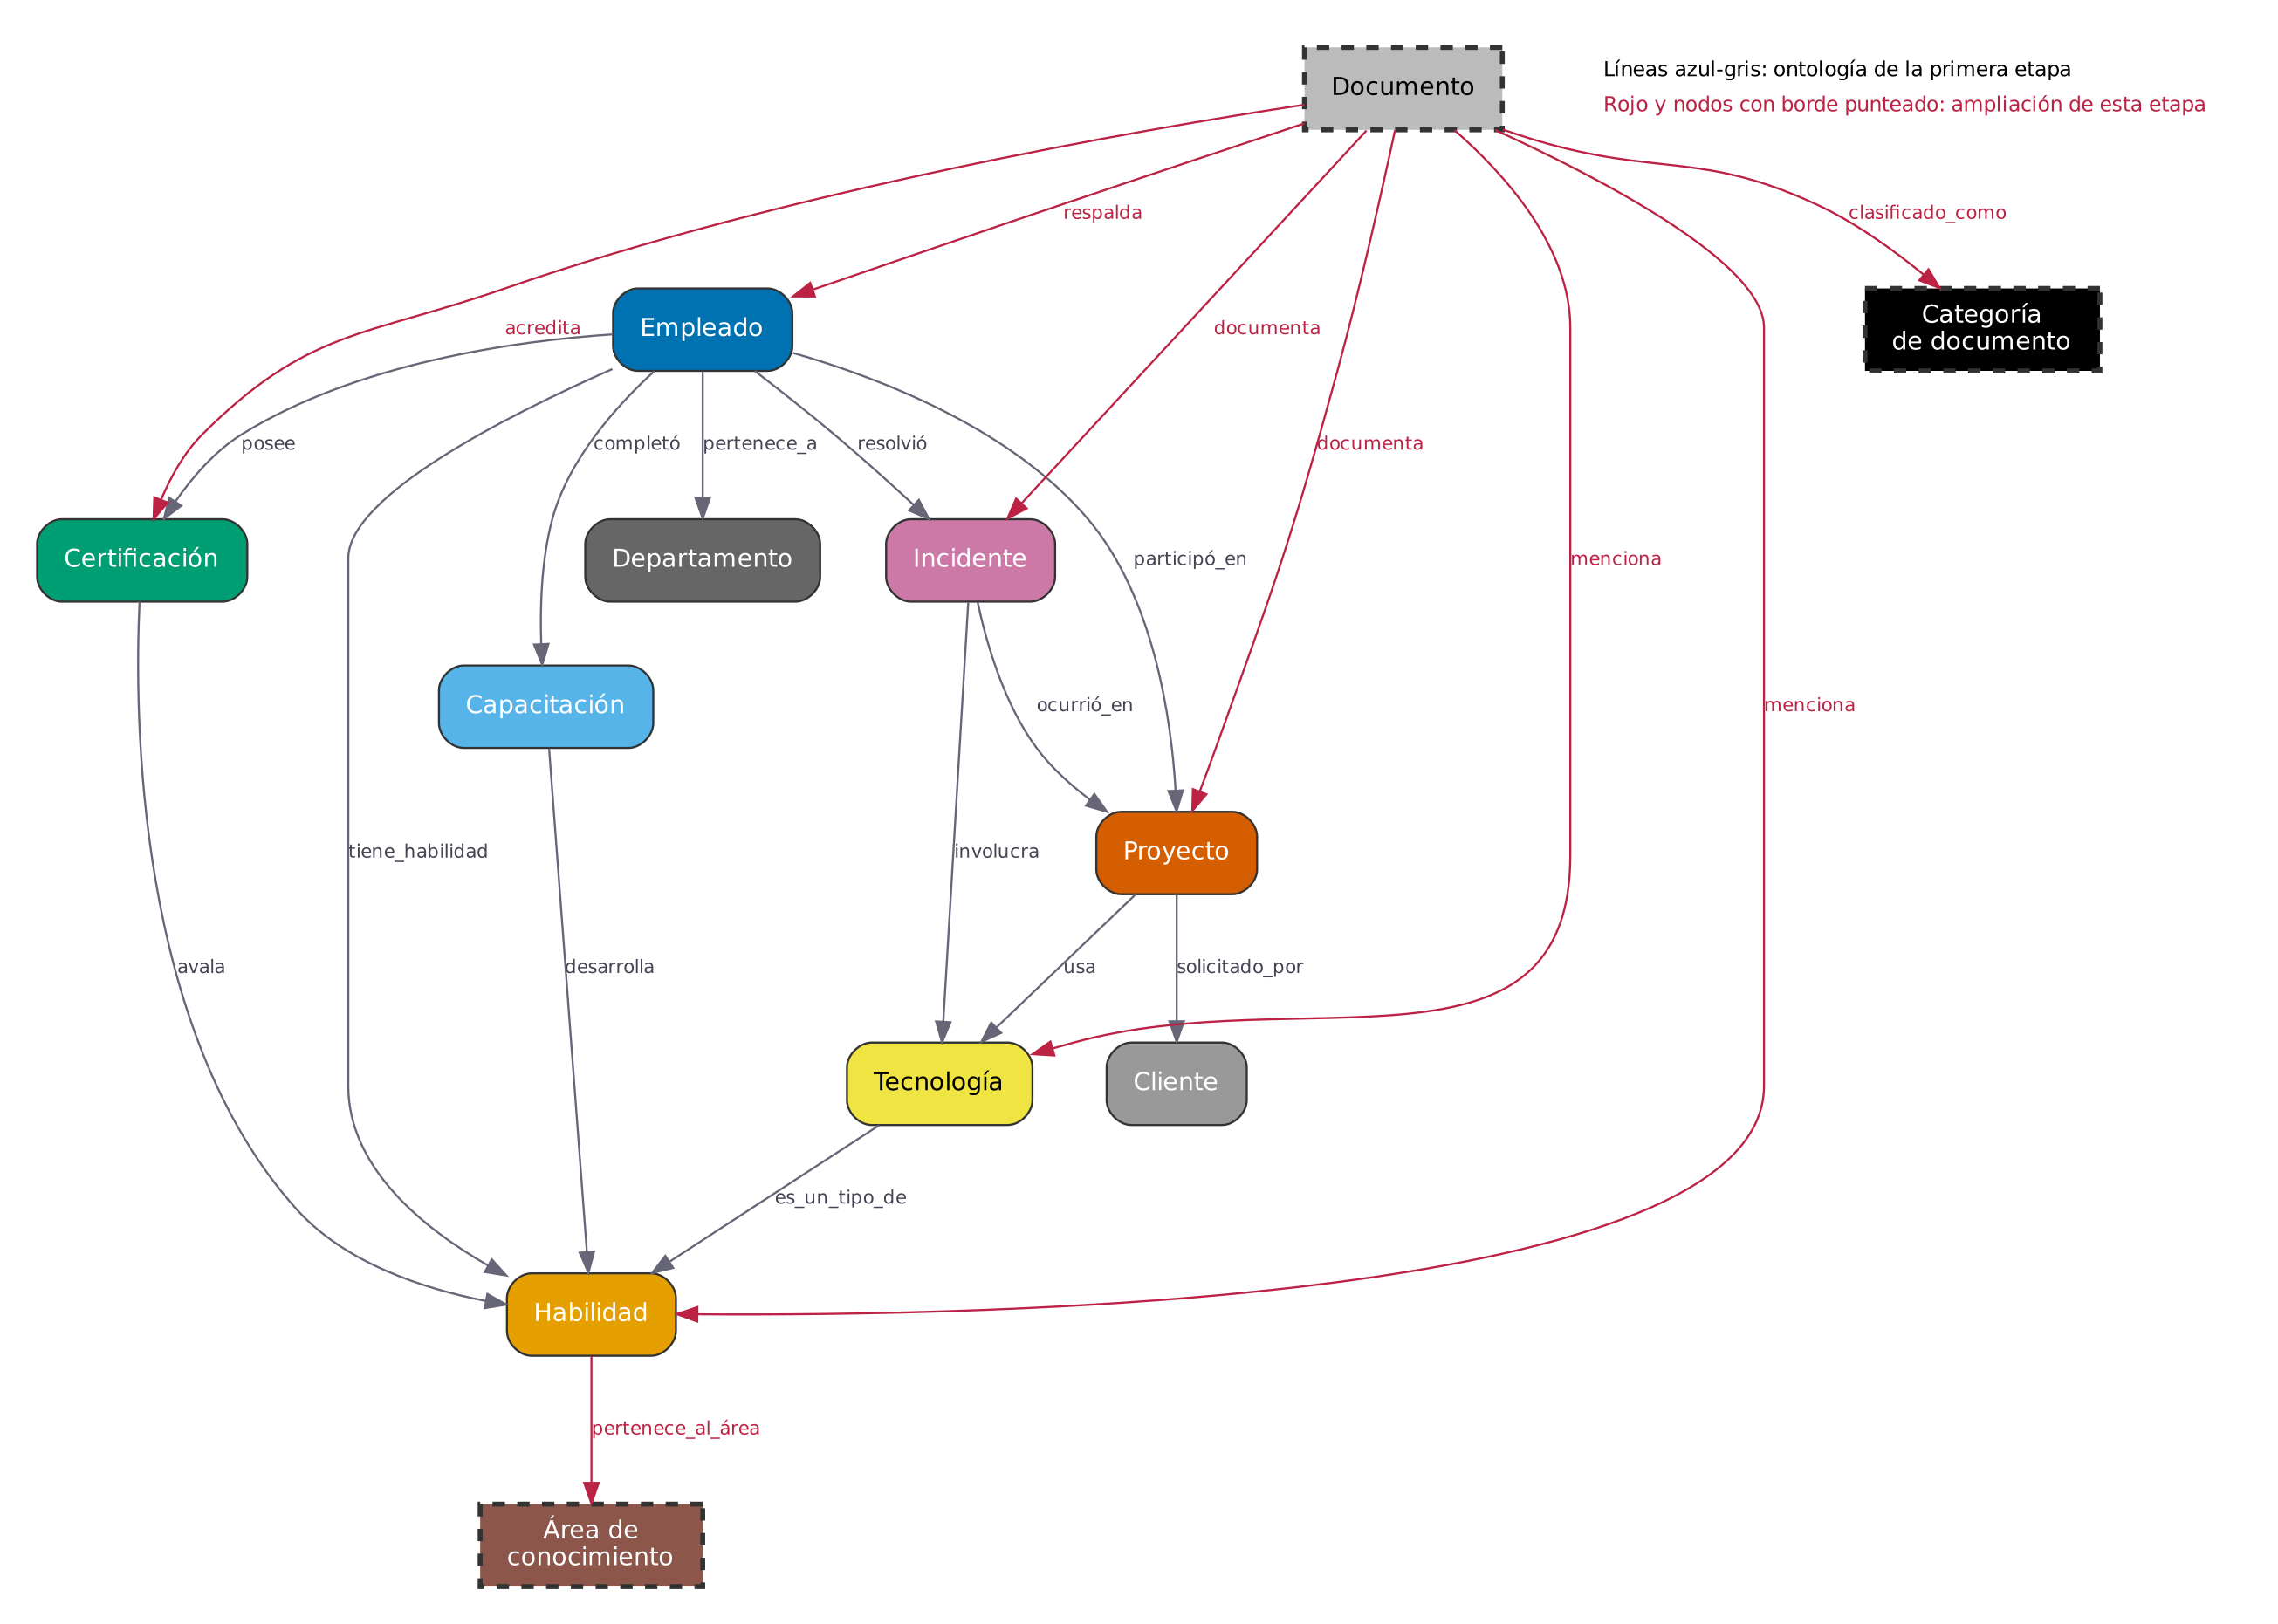

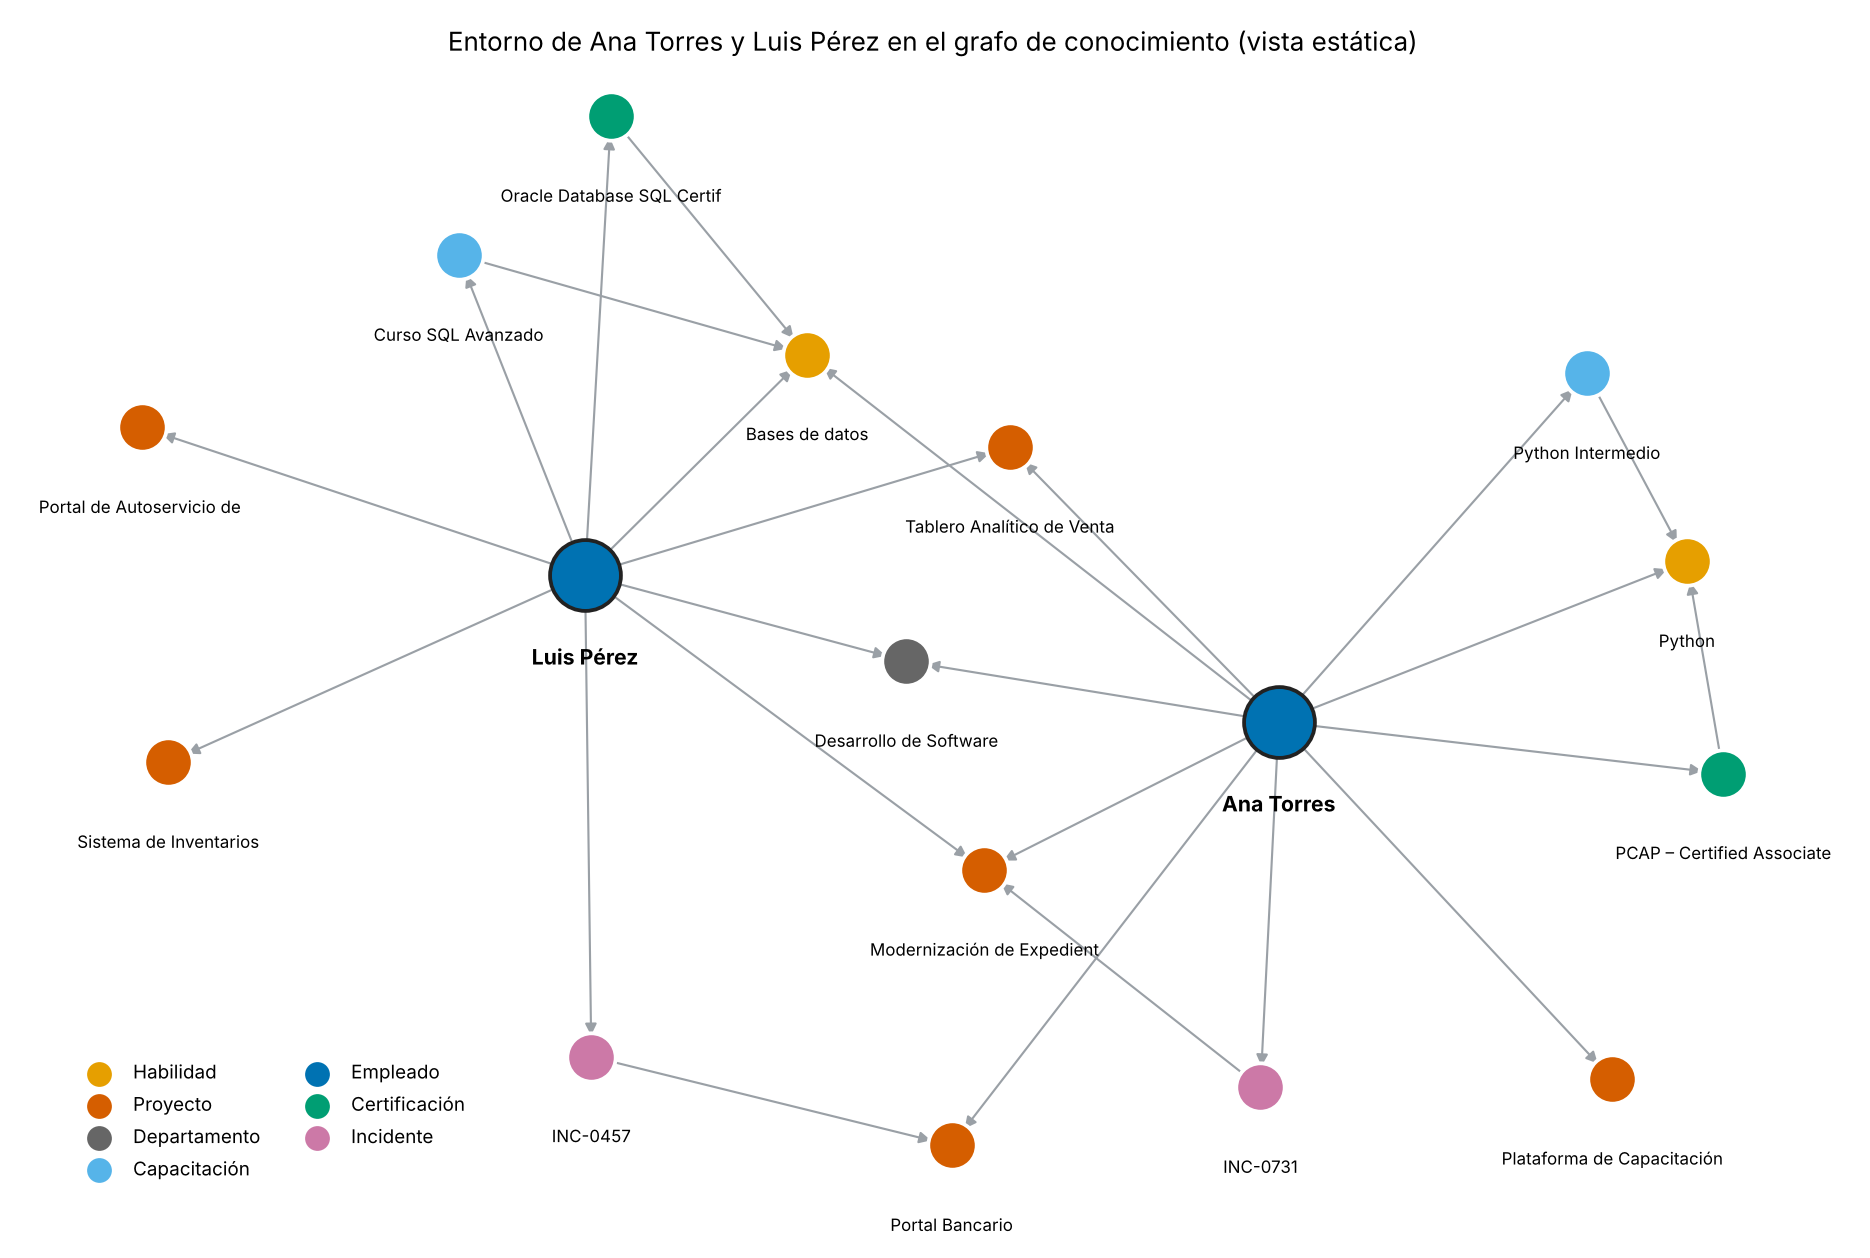

In [6]:
from src.diagrams import arquitectura, ontologia, flujo_ingesta, grafo_estatico
arquitectura(S); ontologia(S); flujo_ingesta(S); grafo_estatico(S)
from IPython.display import Image, display
for f in ['arquitectura','ontologia','grafo_ana_luis']: display(Image('figures/'+f+'.png', width=800))

## 4. Clasificación automática de documentos (NLP + ML)

In [7]:
from src.classifier import ClasificadorDocs
X = [d['texto'] for d in S.kb.docs]; y = [d['categoria'] for d in S.kb.docs]
ev = ClasificadorDocs.evaluar(X, y, k=5)
print(ev['comparacion'].round(3).to_string()); print(); print(ev['reporte'].round(3).to_string())

        modelo  accuracy  precision_macro  recall_macro  f1_macro
0       logreg     0.988            0.986         0.967     0.974
1          svm     0.988            0.986         0.967     0.974
2  naive_bayes     0.982            0.973         0.950     0.957

                               precision  recall  f1-score  support
CV o perfil profesional            0.968   1.000     0.984   30.000
Certificado o constancia           1.000   1.000     1.000   84.000
Informe de cierre de proyecto      1.000   1.000     1.000   12.000
Manual o política interna          1.000   0.800     0.889   10.000
Minuta de reunión                  1.000   1.000     1.000   14.000
Ticket de incidente                0.947   1.000     0.973   18.000
accuracy                           0.988   0.988     0.988    0.988
macro avg                          0.986   0.967     0.974  168.000
weighted avg                       0.989   0.988     0.988  168.000


In [8]:
texto = ("TICKET INC-0999. Severidad: alta. Proyecto afectado: Portal Bancario. Síntoma: la aplicación no responde. "
         "Causa raíz: saturación de conexiones en PostgreSQL. Solución aplicada: ajuste de índices. Responsable: Luis Pérez.")
print(S.analizar_documento(texto)['categoria'])
a = S.analizar_documento(texto)
print({k: round(v,2) for k,v in list(a['probabilidades'].items())[:3]})
for p in a['propuestas']: print(p['origen'], '-', p['relacion'], '->', p['destino'], '(', p['estado'], ')')

Ticket de incidente
{'Ticket de incidente': 0.82, 'Manual o política interna': 0.05, 'Certificado o constancia': 0.05}
EMP-002 - resolvió -> INC-0999 ( propuesto )
INC-0999 - involucra -> PostgreSQL ( propuesto )


## 5. Búsqueda de especialistas con evidencia

In [9]:
res = S.buscador.buscar('Necesitamos una persona con experiencia en Python y bases de datos', k=5)
print(res['requisito'].habilidades, '|', res['tiempo_ms'], 'ms')
for x in res['resultados']:
    print(f"{x['nombre']:<18} cobertura {x['cobertura']}  puntaje {x['puntaje']}")
print(); print(res['resultados'][0]['explicacion'])

['Bases de datos', 'Python'] | 3.9 ms
Emilio Cantú       cobertura 2 de 2  puntaje 81.0
Alejandra Rangel   cobertura 2 de 2  puntaje 75.0
Ana Torres         cobertura 2 de 2  puntaje 71.0
Gabriel Leal       cobertura 2 de 2  puntaje 64.6
Luis Pérez         cobertura 2 de 2  puntaje 64.1

Cumple 2 de 2 requisitos. Bases de datos [comprobada]: Proyecto Portal Bancario (desarrollador backend); usa PostgreSQL; Proyecto Tablero Analítico de Ventas (desarrollador backend); usa PostgreSQL; Proyecto Sistema de Citas Hospitalarias (desarrollador backend); usa PostgreSQL. Python [comprobada]: PCAP – Certified Associate in Python Programming (Python Institute), sin vencimiento; Proyecto Portal Bancario (desarrollador backend); usa Django; Proyecto Tablero Analítico de Ventas (desarrollador backend); usa pandas.


## 6. Recomendación (documentos relacionados y capacitación)

In [10]:
did = S.kb.doc_de(incidente='INC-0457')
for r in S.recomendador.relacionados(did, k=3): print(r['doc_id'], r['titulo'], '| coseno', r['similitud_coseno'], '|', r['motivo'])
print()
hab = {'Python': 2, 'Bases de datos': 2}
obj = S.recomendador.objetivo_desde_texto('quiere especializarse en análisis de datos')
for r in S.recomendador.capacitacion(hab, obj, k=5): print(r['curso'], r['puntaje'], '-', r['por_que'])

D141 Ticket INC-0670 | coseno 0.966 | similitud de contenido 0.97; comparten: Bases de datos, PostgreSQL
D045 Ticket INC-0731 | coseno 0.348 | similitud de contenido 0.35; comparten: Bases de datos, PostgreSQL
D087 Ticket INC-0473 | coseno 0.367 | similitud de contenido 0.37; comparten: PostgreSQL

Pandas para análisis de datos 0.964 - desarrolla el objetivo: Análisis de datos; prerrequisitos cumplidos: Python; nivel intermedio; similitud con su perfil 0.76
Visualización con Power BI 0.914 - desarrolla el objetivo: Análisis de datos; nivel básico; similitud con su perfil 0.43
Proyecto práctico de análisis de datos 0.846 - desarrolla el objetivo: Análisis de datos; prerrequisitos cumplidos: Python, Bases de datos; nivel avanzado; similitud con su perfil 0.91
Estadística aplicada a datos 0.845 - desarrolla el objetivo: Análisis de datos; nivel intermedio; similitud con su perfil 0.50
SQL desde Cero 0.706 - complementa su objetivo «Análisis de datos» (misma área; Bases de datos coincide c

## 7. Asistente conversacional (RAG)
Sin clave de API usa el modo extractivo; con `ANTHROPIC_API_KEY` en el entorno, un LLM redacta usando solo el contexto recuperado.

In [11]:
for q in ['¿Quién resolvió el incidente INC-0457 y cómo?', '¿Cuál es el procedimiento para solicitar un especialista?',
          '¿Cuál es el procedimiento para solicitar un equipo de cómputo nuevo?']:
    r = S.asistente.responder(q)
    print('P:', q); print('R:', r['respuesta'][:500]); print('Fuentes:', r['fuentes'], '| suficiente:', r['suficiente']); print('-'*80)

P: ¿Quién resolvió el incidente INC-0457 y cómo?
R: INC-0457 (alta) en Portal Bancario con PostgreSQL: síntoma «Caída de BD: la aplicación no responde y se agotan las conexiones»; causa: saturación de conexiones; solución: reconfiguración y ajuste de índices; resuelto por Luis Pérez en 3 h. [D049]
Fuentes: ['D049'] | suficiente: True
--------------------------------------------------------------------------------
P: ¿Cuál es el procedimiento para solicitar un especialista?
R: Según «Procedimiento para solicitar un especialista» [D079]:
- Objetivo: formar equipos de proyecto con personal que tenga evidencia comprobable de sus habilidades.
- Paso 1. El líder de proyecto registra la solicitud en ExpertFinder indicando las habilidades requeridas, el nivel mínimo y las fechas.
- Paso 2. El sistema muestra los especialistas ordenados por coincidencia y por solidez de la evidencia.
- Paso 3. El líder revisa las evidencias de cada candidato (certificaciones vigentes, proyect
Fuentes: ['D079', 

## 8. Evaluación completa y métricas

In [12]:
from src.evaluation import ejecutar
m = ejecutar()
import json; print(json.dumps({k: m[k] for k in ['expertos','recomendacion','pruebas_integradas']}, ensure_ascii=False, indent=1, default=str)[:1800])
print({k: v for k, v in m['clasificacion'].items() if k.startswith(('cv_','holdout'))})
print(m['recuperacion']['resumen'])
print(m['chatbot'])

{
 "expertos": {
  "P_at_3": 0.8056,
  "cobertura_R10": 0.9667,
  "tiempo_ms_promedio": 1.93,
  "tiempo_ms_max": 3.74,
  "n_consultas": 12,
  "consultas_sin_resultado": 0
 },
 "recomendacion": {
  "docs_P_at_3": 0.85,
  "docs_similitud_media": 0.7067,
  "docs_n": 20,
  "cap_hit_at_5": 0.8889,
  "cap_NDCG_at_5": 0.9013,
  "cap_casos": 3,
  "cap_detalle": [
   {
    "caso": "Perfil de Daniel: Python básico y SQL; objetivo: especializarse en análisis de datos",
    "objetivo_detectado": "Análisis de datos",
    "recomendados": "Pandas para análisis de datos | Visualización con Power BI | Proyecto práctico de análisis de datos | Estadística aplicada a datos | SQL desde Cero",
    "esperados": "K06, K07, K08",
    "hit_at_5": 0.667,
    "P_at_5": 0.4,
    "NDCG_at_5": 0.704,
    "sin_repetidos": true
   },
   {
    "caso": "Perfil de redes (nivel 3) que quiere aprender nube y DevOps",
    "objetivo_detectado": "Computación en la nube, DevOps",
    "recomendados": "Fundamentos de Azure | Fun

In [13]:
import pandas as pd
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 220)
pd.read_csv('reports/tabla_pruebas.csv')

,Prueba,Tipo,Entrada o consulta,Resultado esperado,Resultado obtenido,¿Cumple?
0,1,Consulta válida,Necesitamos una persona con experiencia en Python y bases de datos,Especialistas con 2 de 2 requisitos y evidencias,"Emilio Cantú (2 de 2, 81.0); Alejandra Rangel (2 de 2, 75.0); Ana Torres (2 de 2, 71.0) · 3.4 ms",Sí
1,2,Consulta similar (sinónimos),alguien que domine py y BD,Mismos especialistas que la prueba 1 (sinónimos normalizados),"Interpretado como: Python, Bases de datos; coincidencia con prueba 1: 5/5 en el top-5",Sí
2,3,Consulta ambigua,necesito a alguien de datos,Resultado justificable: indica cómo interpretó la consulta o pide precisarla,Interpretación: «Interpretación semántica ambigua: «datos» se parece a Análisis de datos (coseno 0.70) y Bases de da...,Sí
3,4,Información inexistente,especialista en Rust,Mensaje de que no hay datos; sin resultados inventados,0 resultados; «No se reconoció ninguna habilidad ni tecnología del catálogo; no se devuelven resultados para no inve...,Sí
4,5,Caso de mayor complejidad,"Kubernetes con certificación vigente y experiencia en Docker, AWS y bases de datos",Ranking por cobertura de varios requisitos; certificación vencida no suma (R2),"Requisitos: Bases de datos, DevOps, Computación en la nube; top: Javier Salinas (3 de 3, 59.7); Héctor Quiroz (3 de ...",Sí
5,6,Asistente: pregunta con respuesta,¿Quién resolvió el incidente INC-0457 y cómo?,"Luis Pérez, con cita del ticket",INC-0457 (alta) en Portal Bancario con PostgreSQL: síntoma «Caída de BD: la aplicación no responde y se agotan las c...,Sí
6,7,Asistente: sin información documental,¿Cuál es el procedimiento para solicitar un equipo de cómputo nuevo?,Reconoce que no hay información y no inventa,"No encontré información suficiente en la base de conocimiento para responder esa pregunta, así que prefiero no inven...",Sí
7,8,Clasificación de documento nuevo,Texto de un ticket de incidente (INC-0999),Categoría «Ticket de incidente»,Ticket de incidente (90%),Sí
8,9,Recomendación de documentos,Documentos relacionados con el ticket INC-0457,Documentos sobre PostgreSQL / bases de datos con similitud mostrada,Ticket INC-0670 (cos 0.966); Ticket INC-0731 (cos 0.348); Ticket INC-0473 (cos 0.367),Sí
9,10,Asistente: pregunta parafraseada,¿Qué norma regula el tratamiento de los datos personales de los colaboradores?,«LFPDPPP» citando la política de privacidad,"No encontré información suficiente en la base de conocimiento para responder esa pregunta, así que prefiero no inven...",No


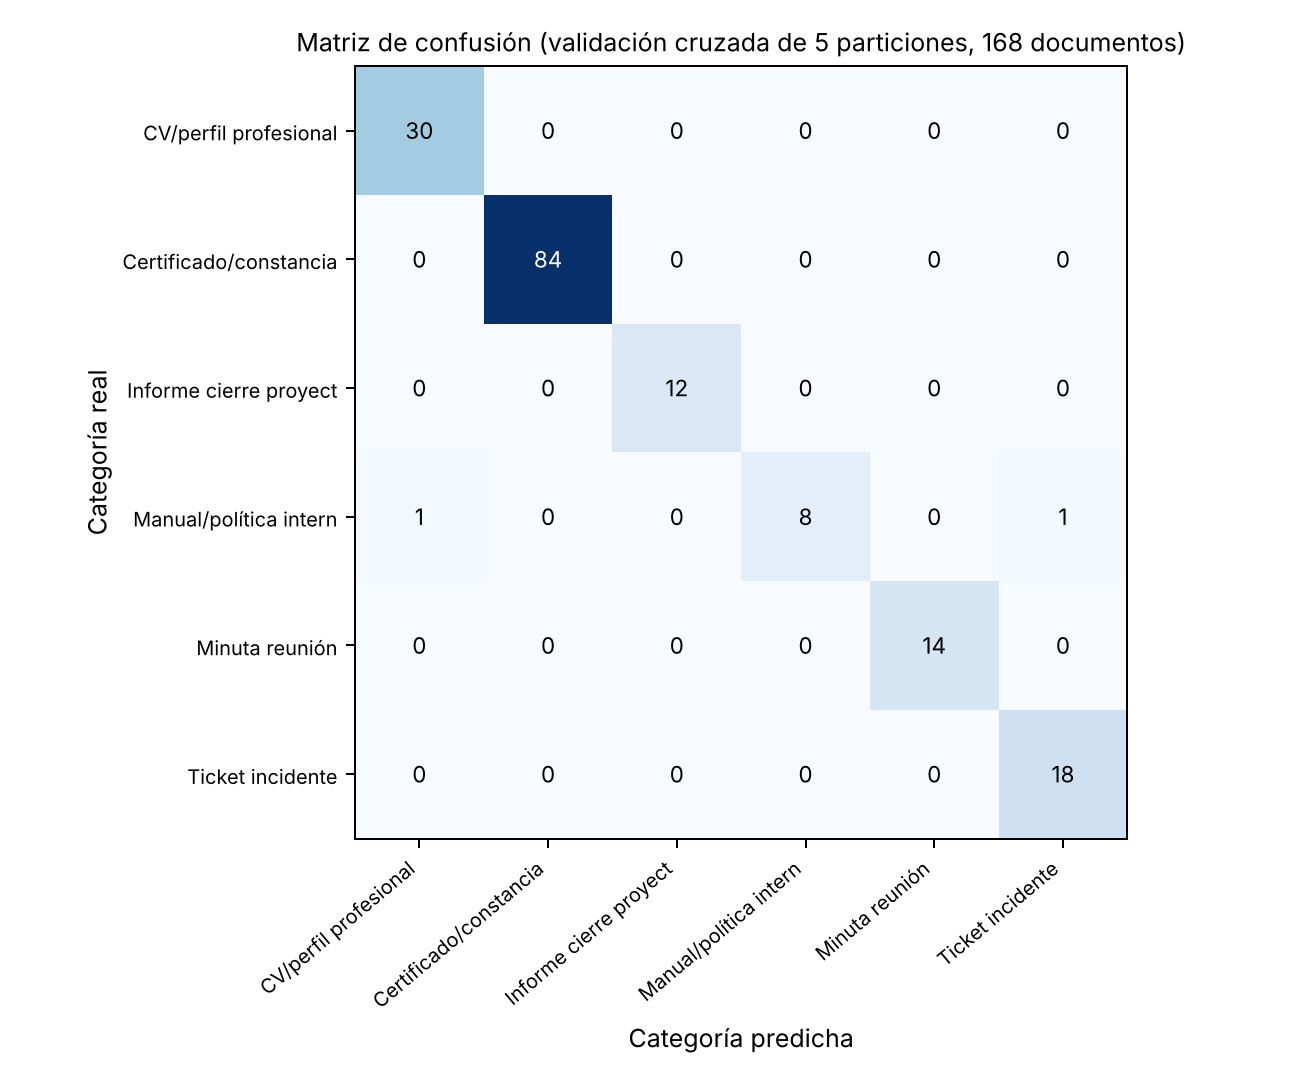

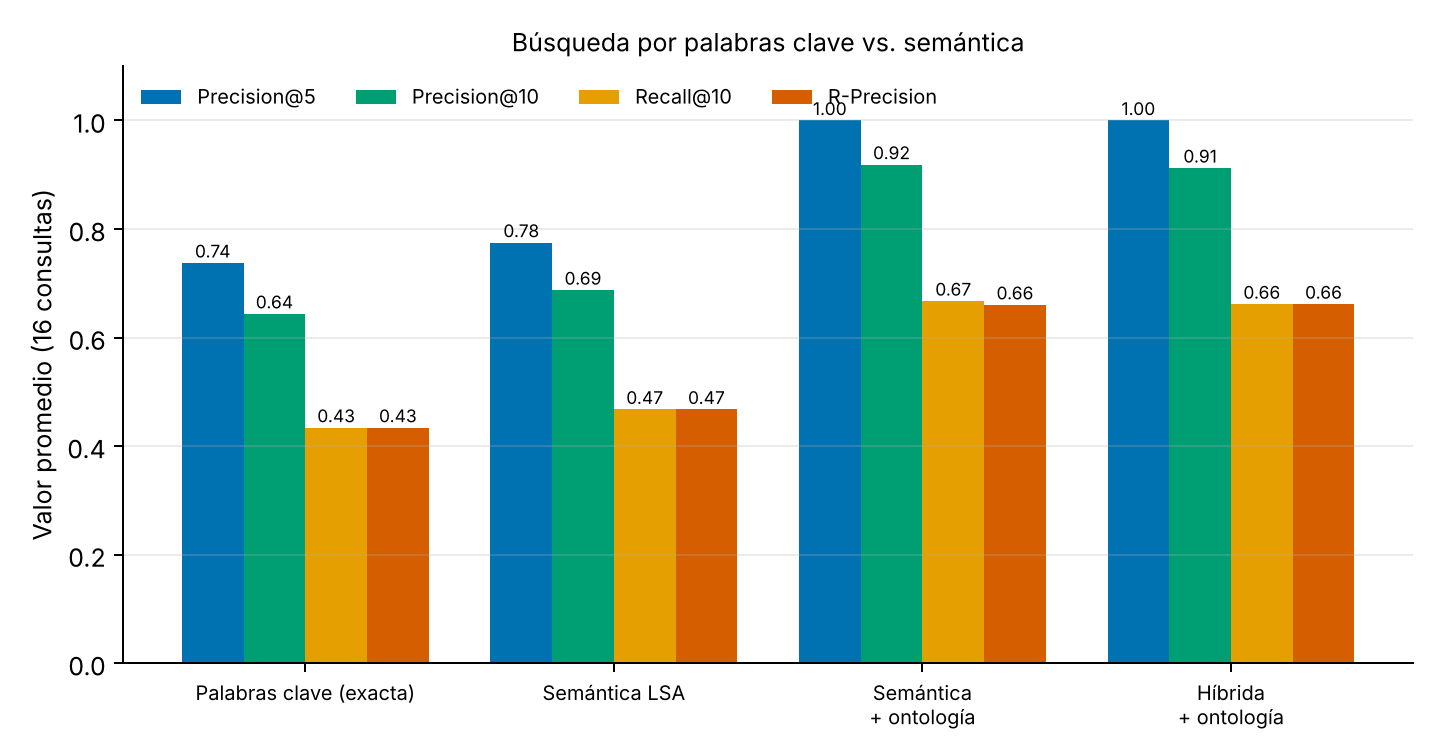

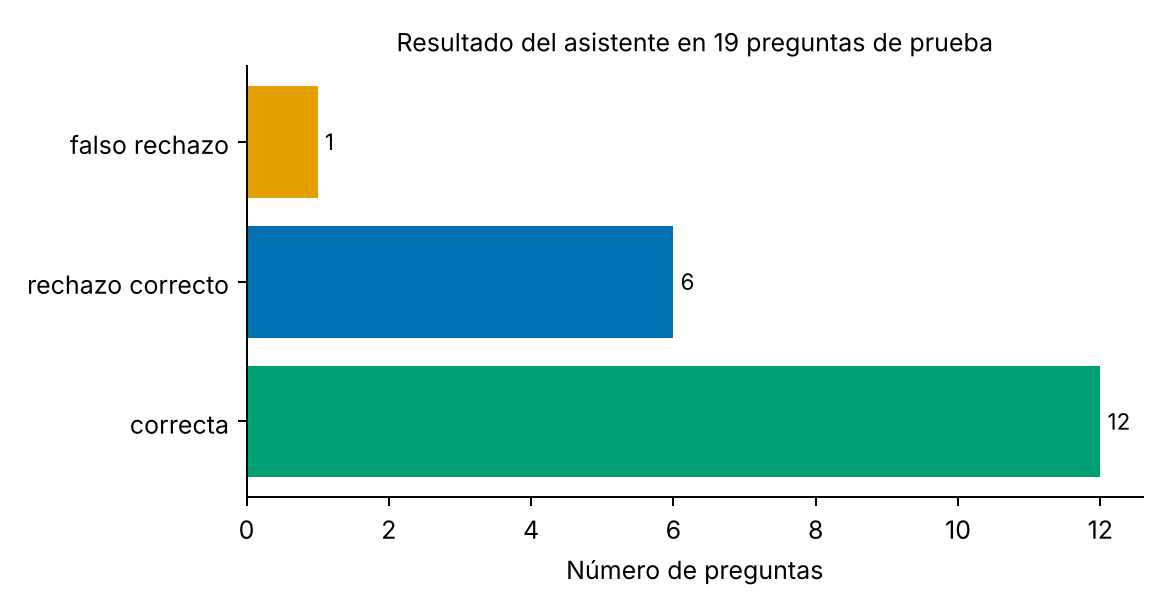

In [14]:
for f in ['matriz_confusion','comparacion_busqueda','chatbot_resultados']: display(Image('figures/'+f+'.png', width=700))

## 9. Ejecutar la interfaz
```bash
streamlit run app.py
```
Para publicarla: sube el repositorio a GitHub y créala en https://share.streamlit.io (archivo principal `app.py`).